In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.ndimage import gaussian_filter1d

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.sans-serif'] = 'Arial' # Choose a nice font here
plt.rcParams['font.size'] = 12 # standard font size
plt.rcParams['mathtext.fontset'] ='dejavusans'
plt.rcParams['mathtext.rm'] = 'Arial'
plt.rcParams['mathtext.it'] = 'Arial'

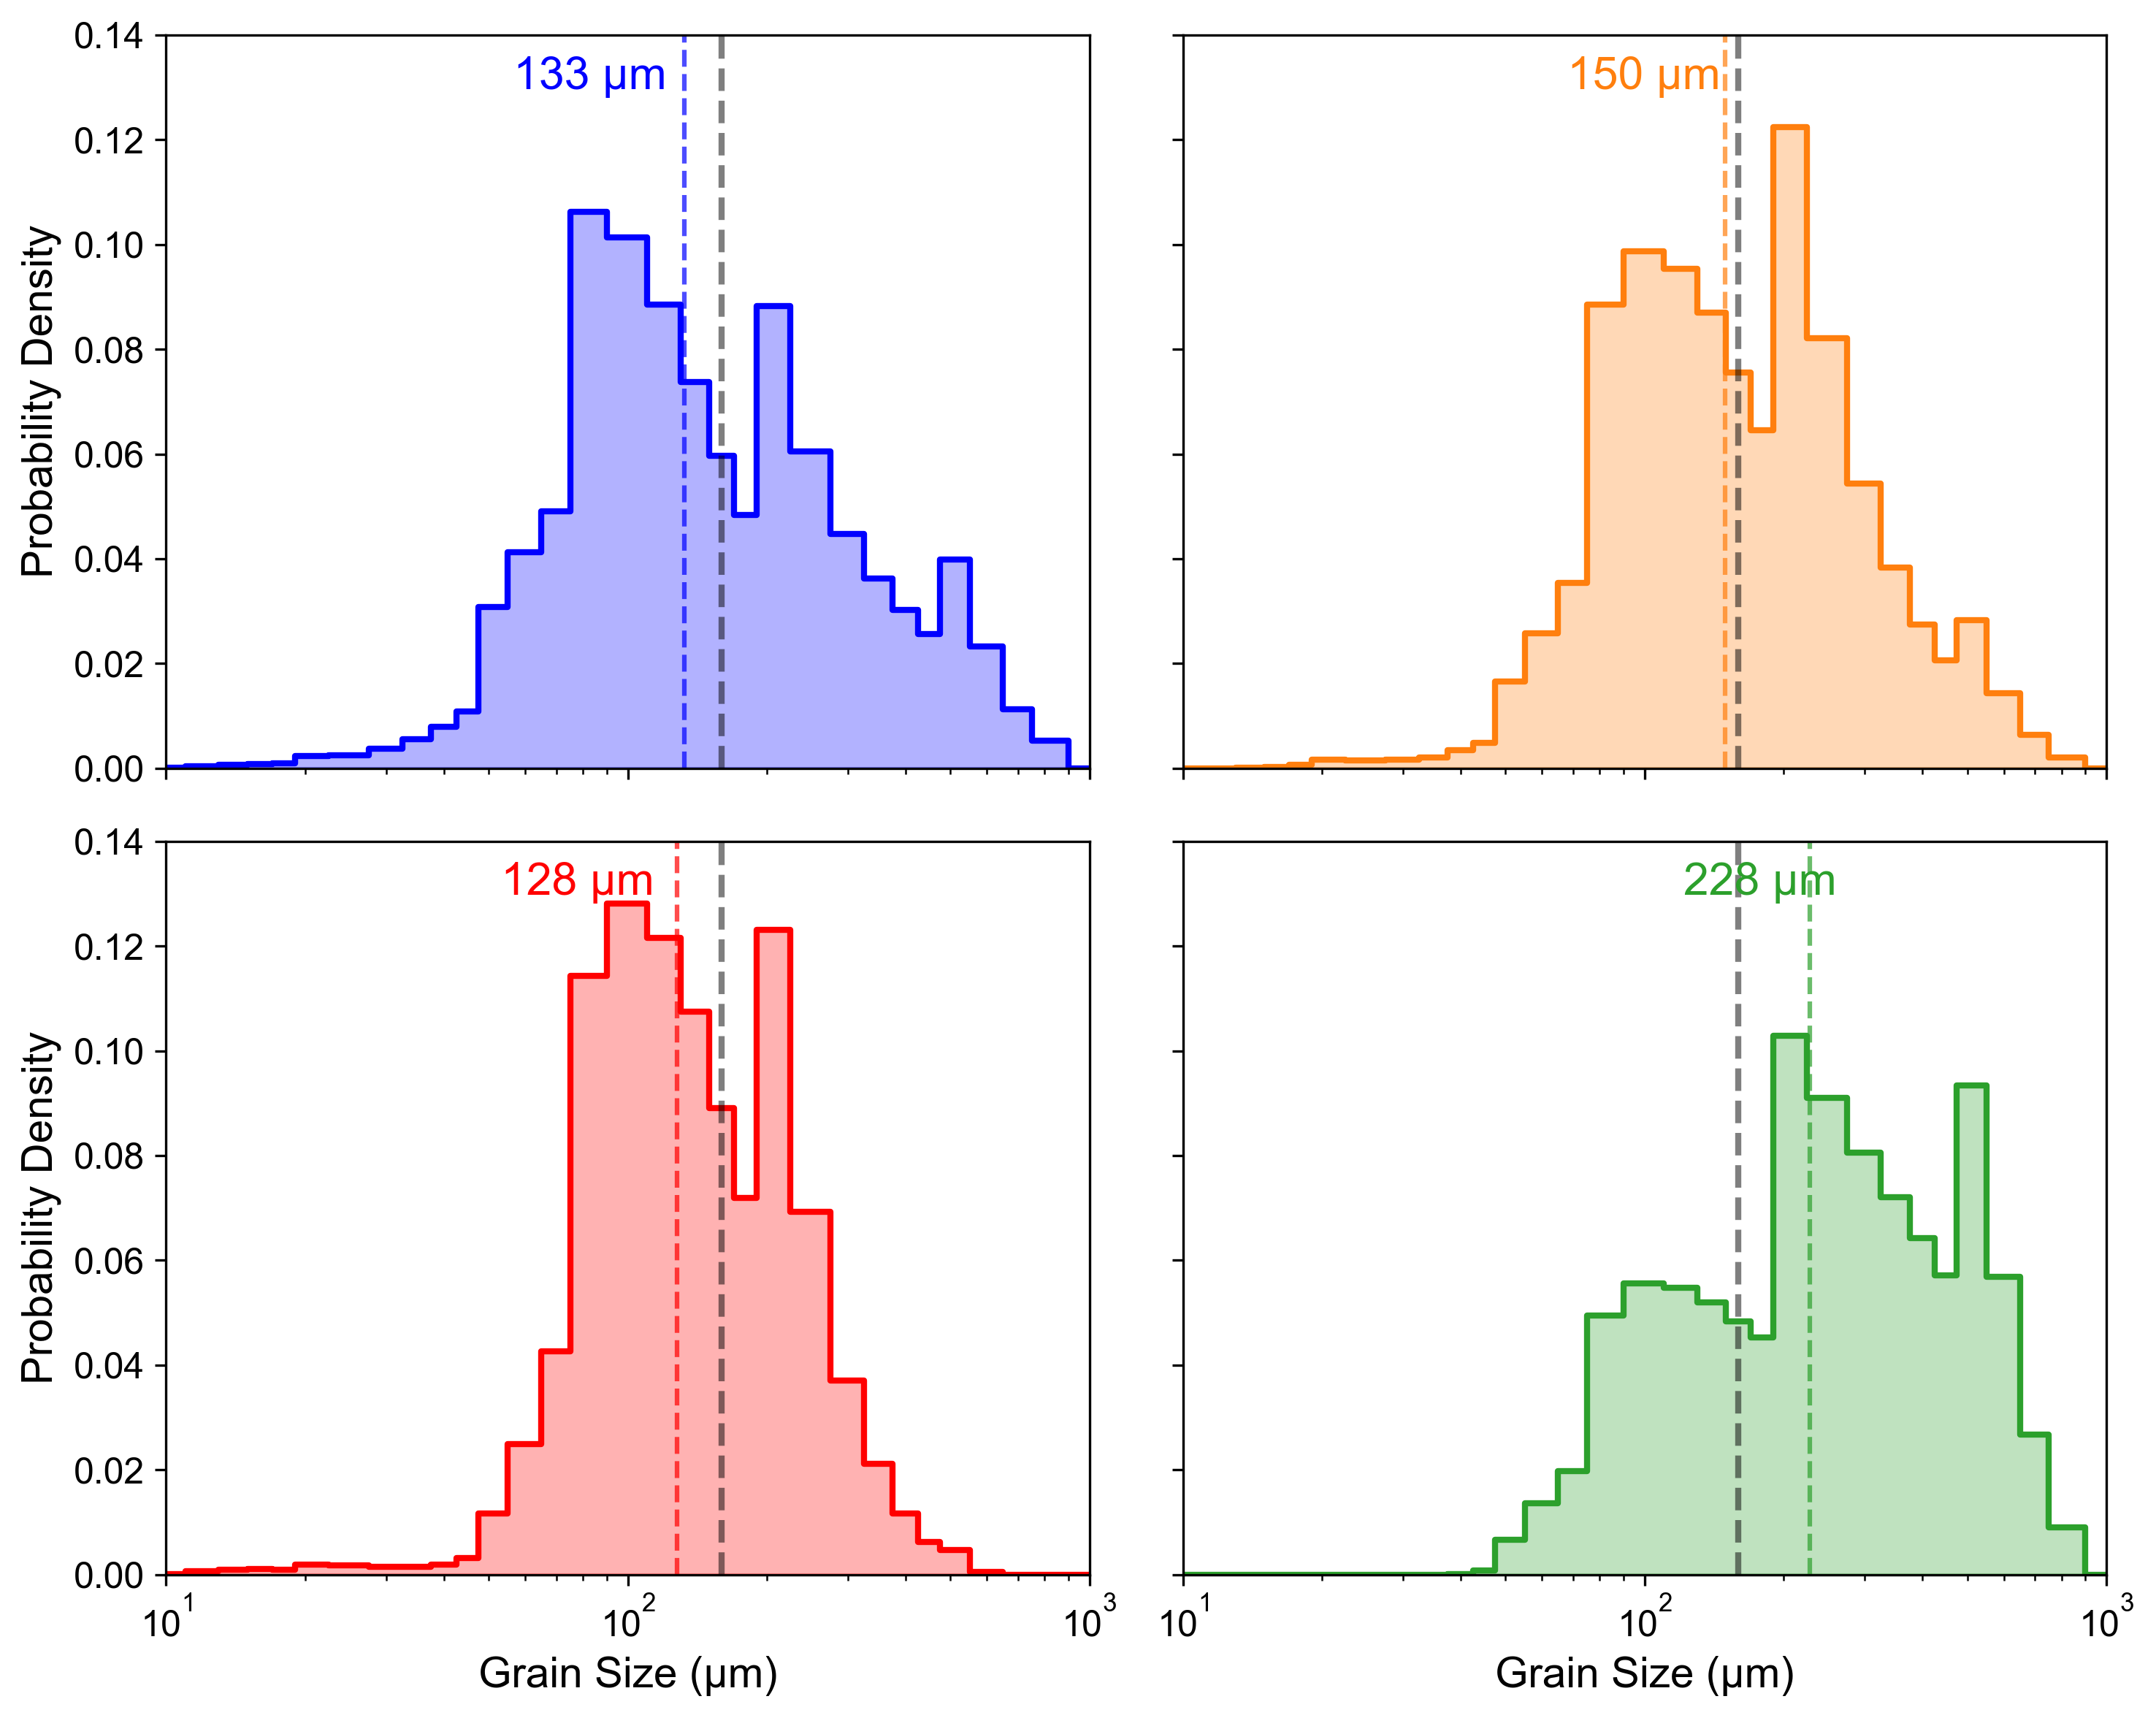

In [8]:
dw1 = pd.read_excel('/Users/ylin0188/Desktop/code box/dfsframework code/1streview/final/grain-size-data.xlsx', sheet_name='1')
dw2 = pd.read_excel('/Users/ylin0188/Desktop/code box/dfsframework code/1streview/final/grain-size-data.xlsx', sheet_name='2')
dw3 = pd.read_excel('/Users/ylin0188/Desktop/code box/dfsframework code/1streview/final/grain-size-data.xlsx', sheet_name='3')
dw4 = pd.read_excel('/Users/ylin0188/Desktop/code box/dfsframework code/1streview/final/grain-size-data.xlsx', sheet_name='4')

def calculate_d50(df):

    cumsum = np.cumsum(df.PDF.values) / np.sum(df.PDF.values)
    idx = np.searchsorted(cumsum, 0.5)
    if idx == 0:
        return df.D.iloc[0]
    elif idx >= len(df.D):
        return df.D.iloc[-1]
    else:
        x1, x2 = df.D.iloc[idx-1], df.D.iloc[idx]
        y1, y2 = cumsum[idx-1], cumsum[idx]
        return x1 + (0.5 - y1) * (x2 - x1) / (y2 - y1)

d50_1 = calculate_d50(dw1)
d50_2 = calculate_d50(dw2)
d50_3 = calculate_d50(dw3)
d50_4 = calculate_d50(dw4)

d50_list = [d50_1, d50_2, d50_3, d50_4]
d50_all = np.mean(d50_list)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

colors = ['blue', '#ff7f0e','red', '#2ca02c']
labels = ['Sample 1', 'Sample 2', 'Sample 3', 'Sample 4']
data = [dw1, dw2, dw3, dw4]
d50s = [d50_1, d50_2, d50_3, d50_4]

for idx, (ax, dw, color, label, d50) in enumerate(zip(axes.flatten(), data, colors, labels, d50s)):
    ax.step(dw.D, dw.PDF/100, where='mid', linewidth=2, color=color)
    ax.fill_between(dw.D, 0, dw.PDF/100, step='mid', alpha=0.3, color=color)
    
    ax.axvline(d50, color=color, linestyle='--', alpha=0.7, linewidth=1.5)
    ax.text(d50-50, 13.6/100, f'{d50:.0f} μm', 
            color=color, ha='center', va='top', fontsize=15)
    
    ax.axvline(d50_all, color='black', linestyle='--', alpha=0.5, linewidth=2)
    
    row = idx // 2
    col = idx % 2

    # ax.grid(True, alpha=0.3)
    ax.set_xscale('log')
    ax.set_xlim(10, 1000)
    ax.set_ylim(0, 0.14) 

    if row == 1: 
        ax.set_xlabel('Grain Size (μm)', fontsize=14)
    else:         
        ax.set_xlabel('')
        ax.set_xticklabels([])
    
    if col == 0:  
        ax.set_ylabel('Probability Density', fontsize=14)
    else:
        ax.set_ylabel('')
        ax.set_yticklabels([])
    


plt.tight_layout()
plt.show()

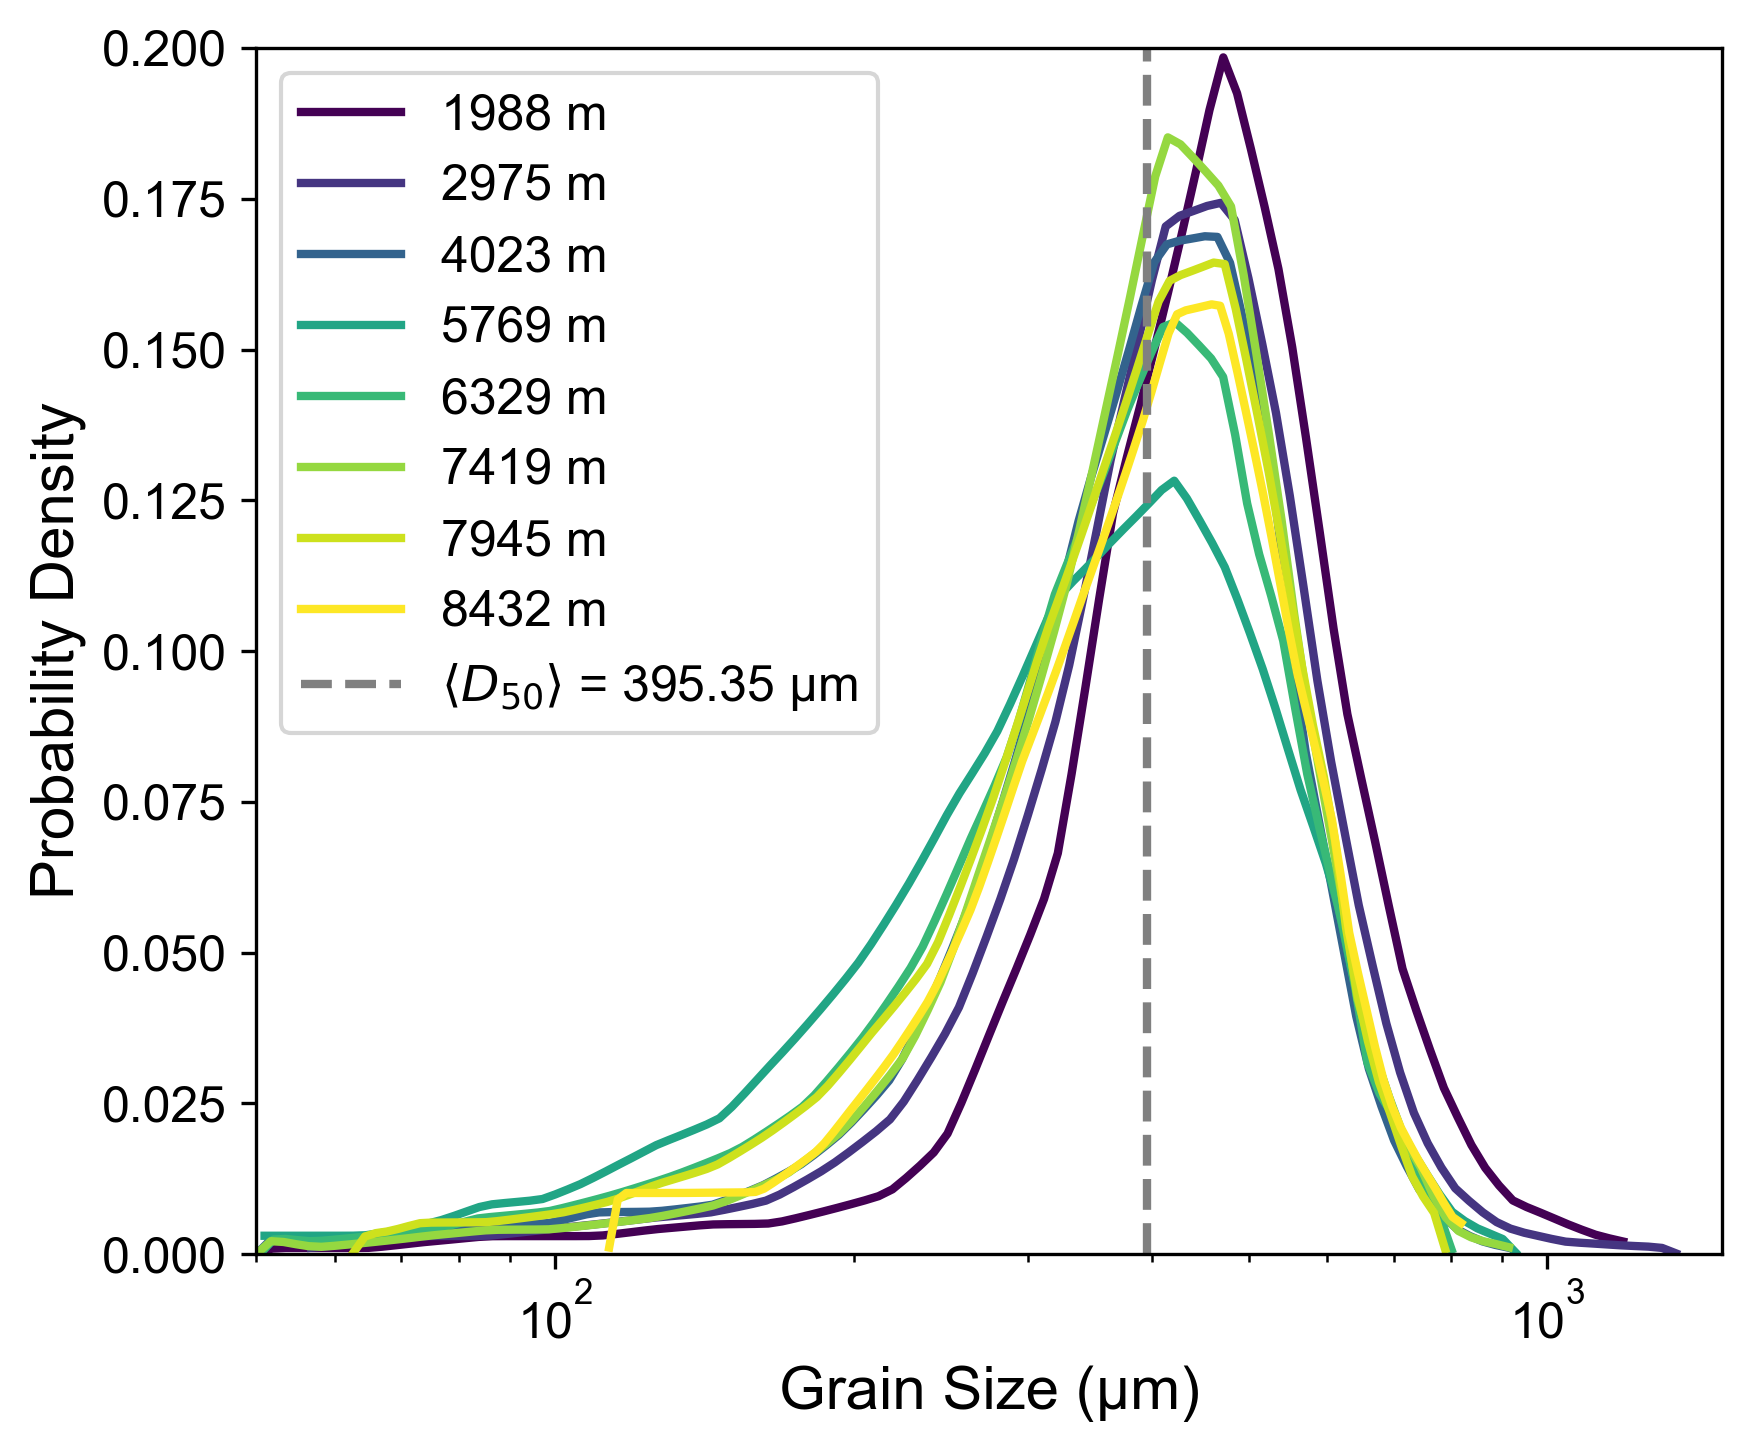

In [9]:
dwws = pd.read_excel('/Users/ylin0188/Desktop/code box/dfsframework code/1streview/final/grain-size-data.xlsx', sheet_name='WS')

col_names = dwws.columns.tolist()
n_pairs = len(col_names) // 2

plt.figure(figsize=(6, 5))


sample_values = []
for i in range(n_pairs):
    try:
        val = float(col_names[i*2])
        sample_values.append(val)
    except:
        sample_values.append(i)

norm_values = (np.array(sample_values) - np.min(sample_values)) / (np.max(sample_values) - np.min(sample_values))
cmap = plt.cm.viridis

d50_list = []

def calculate_d50_from_interp(x_interp, y_smooth):
    cumsum = np.cumsum(y_smooth) / np.sum(y_smooth)
    idx = np.searchsorted(cumsum, 0.5)
    if idx == 0:
        return x_interp[0]
    elif idx >= len(x_interp):
        return x_interp[-1]
    else:
        x1, x2 = x_interp[idx-1], x_interp[idx]
        y1, y2 = cumsum[idx-1], cumsum[idx]
        return x1 + (0.5 - y1) * (x2 - x1) / (y2 - y1)

for i in range(n_pairs):
    x_col = col_names[i*2]
    y_col = col_names[i*2 + 1]
    
    x_data = dwws[x_col].values[1:].astype(float)*1000
    y_data = dwws[y_col].values[1:].astype(float)
    
    valid = np.isfinite(x_data) & np.isfinite(y_data)
    x_data = x_data[valid]
    y_data = y_data[valid]
    
    if len(x_data) < 2:
        continue
    
    x_min = x_data.min()
    x_max = x_data.max()
    x_interp = np.logspace(np.log10(x_min), np.log10(x_max), 100)

    f = interp1d(x_data, y_data, kind='linear', bounds_error=False, fill_value=0)
    y_interp = f(x_interp)
    

    sigma = 0.5
    y_smooth = gaussian_filter1d(y_interp, sigma=sigma)
    
    color = cmap(norm_values[i])
    
    d50 = calculate_d50_from_interp(x_interp, y_smooth)
    d50_list.append(d50)
    
    plt.plot(x_interp, y_smooth, '-', color=color, linewidth=2, 
             label=f'{sample_values[i]:.0f} m')

d50_all = np.mean(d50_list)
plt.axvline(d50_all, color='grey', linestyle='--', linewidth=2, 
            label=f'$\\langle D_{{50}} \\rangle$ = {d50_all:.2f} μm')

plt.xlabel('Grain Size (μm)', fontsize=12*1.2)
plt.ylabel('Probability Density', fontsize=12*1.2)

handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(loc='upper left')

plt.xscale('log')
plt.xlim(50, 1500)
plt.ylim(0, .2)
plt.tight_layout()
plt.show()